# Analyzing Wildfire Activities in Australia

**CISC7204 Assignment 02 - Module 05 Practice Project, Lab 01**
ZHOU ZHIFAN | MC651611

## Objectives

This notebook takes a satellite-derived fire record for Australia and asks four
questions of it:

1. Which regions carry the most fire activity?
2. How has the total burned area changed between 2005 and 2020?
3. Is there a seasonal pattern, and how strong is it?
4. Does the radiative power of a fire track its estimated area?

Each question is answered with one chart and a short reading of that chart.

## About the data

`Historical_Wildfires.csv` is a daily, region-level record. Each row is one
region on one day, not one fire, so the columns are daily aggregates:

| Column | Meaning |
|---|---|
| `Region` | Australian state or territory abbreviation |
| `Date` | Calendar date of the observation |
| `Estimated_fire_area` | Estimated burned area for that region-day, in km² x 100 |
| `Mean_estimated_fire_brightness` | Mean brightness temperature of detected fire pixels |
| `Mean_estimated_fire_radiative_power` | Mean radiative power released (MW per pixel) |
| `Mean_confidence` | Mean detection confidence |
| `Count` | Number of fire pixels detected |

The date column is written month/day/year, which has to be stated explicitly
when parsing, because day-first parsing would silently misread every date.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import folium

%matplotlib inline
mpl.style.use('ggplot')

In [2]:
URL = ('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/'
       'IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/Historical_Wildfires.csv')

df = pd.read_csv(URL)
print('Data read into a pandas dataframe!')
df.head()

Data read into a pandas dataframe!


,Region,Date,Estimated_fire_area,Mean_estimated_fire_brightness,Mean_estimated_fire_radiative_power,Mean_confidence,Std_confidence,Var_confidence,Count,Replaced
0,NSW,1/4/2005,8.68000,312.266667,42.400000,78.666667,2.886751,8.333333,3,R
1,NSW,1/5/2005,16.61125,322.475000,62.362500,85.500000,8.088793,65.428571,8,R
2,NSW,1/6/2005,5.52000,325.266667,38.400000,78.333333,3.214550,10.333333,3,R
3,NSW,1/7/2005,6.26400,313.870000,33.800000,92.200000,7.529940,56.700000,5,R
4,NSW,1/8/2005,5.40000,337.383333,122.533333,91.000000,7.937254,63.000000,3,R


In [3]:
# size of the dataset and the type of each column
print('rows and columns:', df.shape)
df.info()

rows and columns: (26406, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26406 entries, 0 to 26405
Data columns (total 10 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Region                               26406 non-null  object 
 1   Date                                 26406 non-null  object 
 2   Estimated_fire_area                  26406 non-null  float64
 3   Mean_estimated_fire_brightness       26406 non-null  float64
 4   Mean_estimated_fire_radiative_power  26406 non-null  float64
 5   Mean_confidence                      26406 non-null  float64
 6   Std_confidence                       24199 non-null  float64
 7   Var_confidence                       24199 non-null  float64
 8   Count                                26406 non-null  int64  
 9   Replaced                             26406 non-null  object 
dtypes: float64(6), int64(1), object(3)
memory usage: 2.0+ MB


In [4]:
# the dates are stored as month/day/year, so the format is given explicitly
df['Date'] = pd.to_datetime(df['Date'], format='%m/%d/%Y')

# year and month are used in the charts below
df['Year'] = df['Date'].dt.year
df['Month'] = df['Date'].dt.month

print('period covered:', df['Date'].min().date(), 'to', df['Date'].max().date())
print('regions:', sorted(df['Region'].unique()))

period covered: 2005-01-01 to 2020-10-31
regions: ['NSW', 'NT', 'QL', 'SA', 'TA', 'VI', 'WA']


In [5]:
# summary statistics of the numeric columns
df[['Estimated_fire_area', 'Mean_estimated_fire_brightness',
    'Mean_estimated_fire_radiative_power', 'Count']].describe()

,Estimated_fire_area,Mean_estimated_fire_brightness,Mean_estimated_fire_radiative_power,Count
count,26406.000000,26406.000000,26406.000000,26406.000000
mean,144.297966,319.662078,83.621258,72.059305
std,314.453847,8.862005,67.510022,150.973128
min,1.000000,290.700000,0.000000,1.000000
25%,8.911875,313.933333,44.150391,5.000000
50%,38.434091,319.784412,67.133333,20.000000
75%,146.951278,325.403144,103.123611,74.000000
max,10120.943170,381.950000,2178.600000,3954.000000


## Question 1 - Which regions carry the most fire activity?

Summing the estimated burned area over the whole period, by region.

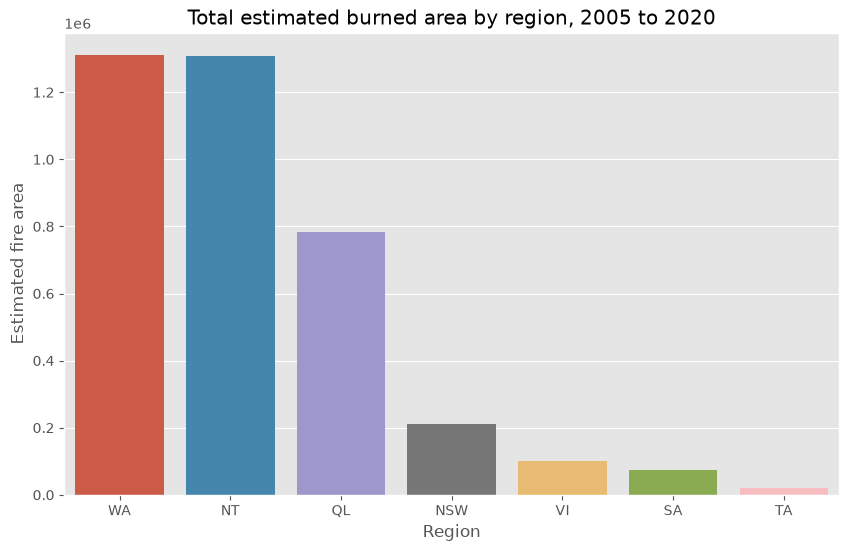

,Region,Estimated_fire_area
0,WA,1.311462e+06
1,NT,1.308160e+06
2,QL,7.827472e+05
3,NSW,2.115994e+05
4,VI,1.001949e+05
5,SA,7.466470e+04
6,TA,2.150453e+04


In [6]:
area_by_region = (df.groupby('Region')['Estimated_fire_area'].sum()
                    .sort_values(ascending=False).reset_index())

plt.figure(figsize=(10, 6))
sns.barplot(data=area_by_region, x='Region', y='Estimated_fire_area', hue='Region', legend=False)
plt.title('Total estimated burned area by region, 2005 to 2020')
plt.xlabel('Region')
plt.ylabel('Estimated fire area')
plt.show()

area_by_region

**Reading the chart.** The Northern Territory and Western Australia account for
the largest share of the total, which is expected: both are vast and sparsely
populated, so a large absolute burned area does not mean a large population is
at risk. Victoria and Tasmania sit at the other end. Because these are totals
over sixteen years, the chart says nothing about how concentrated any single
year was - that is Question 2.

## Question 2 - How has the total burned area changed over time?

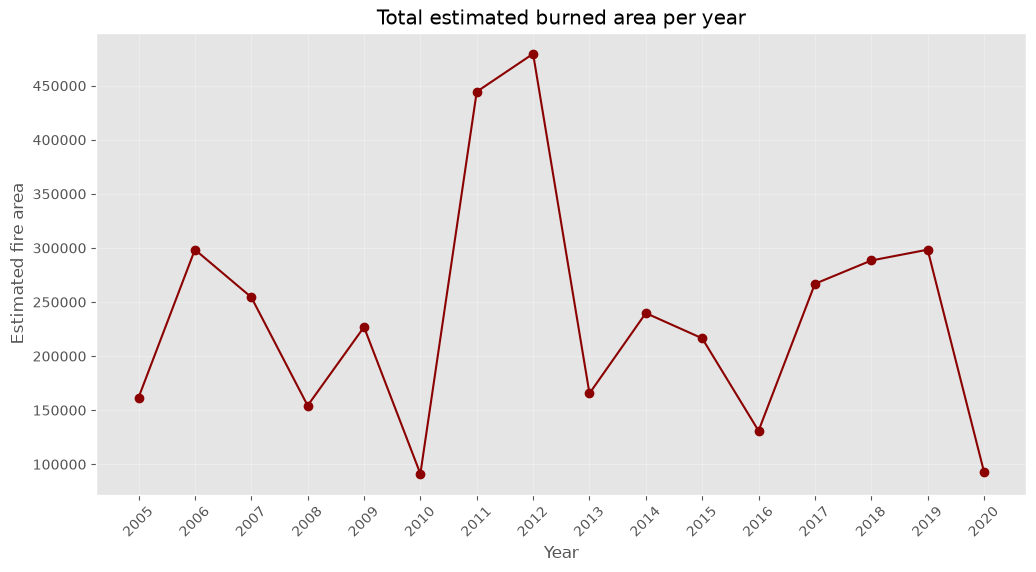

In [7]:
area_by_year = (df.groupby('Year')['Estimated_fire_area'].sum().reset_index())

plt.figure(figsize=(12, 6))
plt.plot(area_by_year['Year'], area_by_year['Estimated_fire_area'], marker='o', color='darkred')
plt.title('Total estimated burned area per year')
plt.xlabel('Year')
plt.ylabel('Estimated fire area')
plt.xticks(area_by_year['Year'], rotation=45)
plt.grid(True, alpha=0.3)
plt.show()

**Reading the chart.** The series is volatile rather than trending: 2011 and
2012 are the two largest years in the record, 2010 and 2020 the smallest, and
2020 is only a partial year (the data stop in October), so its low total is a
coverage artefact rather than a quiet fire season. That distinction matters -
it is the kind of thing a reader would otherwise take at face value.

## Question 3 - Is there a seasonal pattern?

Australian fire seasons differ by latitude, so this pools all regions and asks
which months contribute most of the burned area.

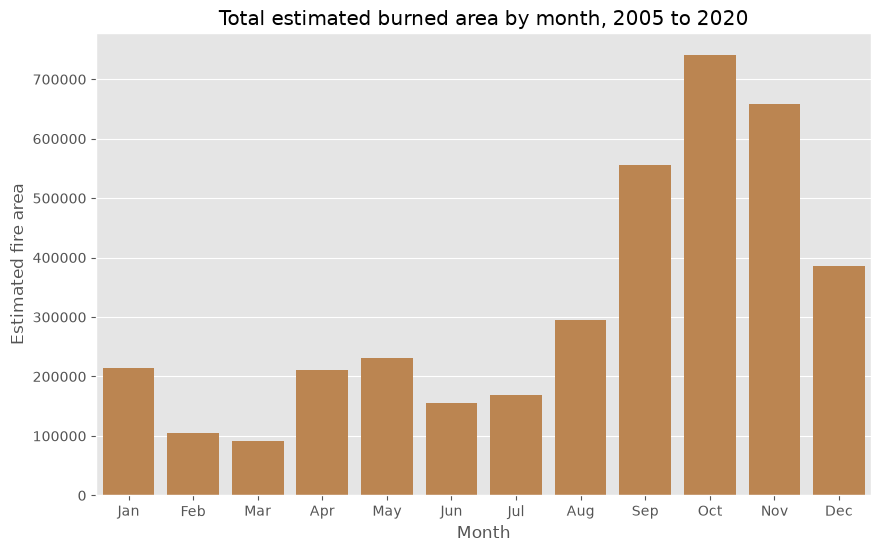

In [8]:
area_by_month = (df.groupby('Month')['Estimated_fire_area'].sum().reindex(range(1, 13)).reset_index())
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
area_by_month['Month name'] = month_names

plt.figure(figsize=(10, 6))
sns.barplot(data=area_by_month, x='Month name', y='Estimated_fire_area', color='peru')
plt.title('Total estimated burned area by month, 2005 to 2020')
plt.xlabel('Month')
plt.ylabel('Estimated fire area')
plt.show()

**Reading the chart.** Activity builds through the second half of the year and
peaks in October, with September to November carrying most of the burned area,
while March to May are the quietest months. That is consistent with the
southern-hemisphere fire season, and it is a stronger pattern than the
year-to-year variation in Question 2.

## Question 4 - Does radiative power track fire area?

Radiative power measures how much energy the detected fire pixels release,
which is a proxy for intensity rather than extent. A log scale is used on both
axes because both variables span several orders of magnitude.

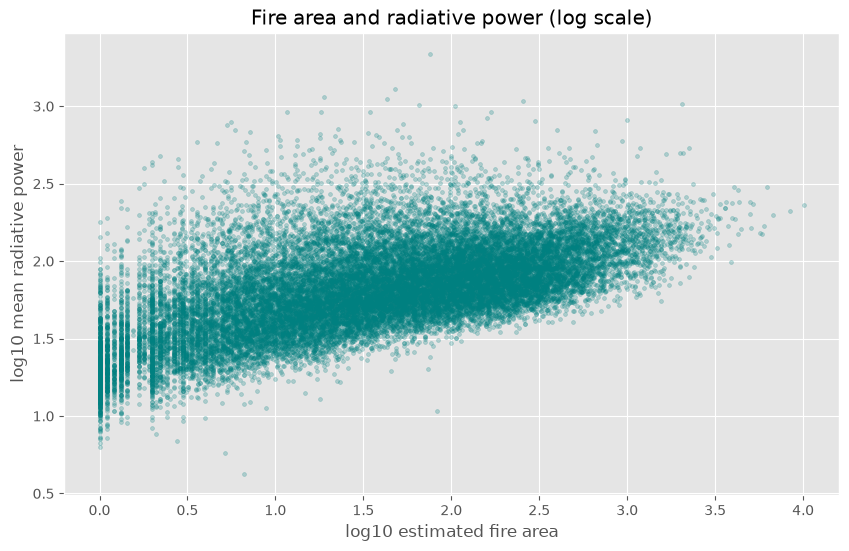

correlation on log scales: 0.589


In [9]:
plot_df = df[(df['Estimated_fire_area'] > 0) &
             (df['Mean_estimated_fire_radiative_power'] > 0)]

plt.figure(figsize=(10, 6))
plt.scatter(np.log10(plot_df['Estimated_fire_area']),
            np.log10(plot_df['Mean_estimated_fire_radiative_power']),
            alpha=0.25, s=8, color='teal')
plt.title('Fire area and radiative power (log scale)')
plt.xlabel('log10 estimated fire area')
plt.ylabel('log10 mean radiative power')
plt.show()

print('correlation on log scales:',
      round(np.corrcoef(np.log10(plot_df['Estimated_fire_area']),
                        np.log10(plot_df['Mean_estimated_fire_radiative_power']))[0, 1], 3))

**Reading the chart.** The cloud is clearly positive but far from a straight
line: larger fires tend to release more power per pixel, yet the spread at any
given area is wide. Area and intensity are related but not interchangeable, so
a ranking of regions by burned area would not be the same as a ranking by
intensity.

## Question 5 - Where is the activity concentrated?

The same regional totals as Question 1, drawn on a map. The circle radius is
proportional to the total burned area of that region.

In [10]:
centroids = {
    'WA':  [-25.04, 121.30],
    'NT':  [-19.49, 132.55],
    'SA':  [-30.00, 136.21],
    'QL':  [-20.92, 142.70],
    'NSW': [-31.25, 146.92],
    'VI':  [-37.02, 144.28],
    'TA':  [-41.45, 146.65],
}

australia_map = folium.Map(location=[-25.0, 134.0], zoom_start=4)
max_area = area_by_region['Estimated_fire_area'].max()

for _, row in area_by_region.iterrows():
    lat, lon = centroids[row['Region']]
    radius = 8 + 32 * (row['Estimated_fire_area'] / max_area)
    folium.CircleMarker(
        location=[lat, lon],
        radius=radius,
        color='darkred',
        fill=True,
        fill_color='orangered',
        fill_opacity=0.45,
        popup=f"{row['Region']}: {row['Estimated_fire_area']:,.0f}",
    ).add_to(australia_map)

australia_map

## What the analysis shows

Three findings are robust enough to state plainly. Fire activity is
concentrated in the Northern Territory and Western Australia by total area.
The seasonal cycle is sharper than the year-to-year trend, peaking in October.
And intensity and extent move together only loosely, which is why the two are
reported separately rather than merged into one severity score.

Two limits apply. Every row is a region-day aggregate, so nothing here
describes an individual fire, and nothing here connects burned area to
population, property or suppression effort. The 2020 total is also incomplete,
because the record stops at the end of October.